Code for the final for MATH 132B
Optimal Transport for image color adaptation

In [2]:
import os
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
import ot
from PIL import Image


In [ ]:
# Change the filenames of the images here
img1_name = '/Users/User/Example/img1.jpg'
img2_name = '/Users/User/Example/img2.jpg'

In [4]:
def im2mat(img):
    """Converts an image to matrix (one pixel per line)"""
    return img.reshape((img.shape[0] * img.shape[1], img.shape[2]))


def mat2im(X, shape):
    """Converts back a matrix to an image"""
    return X.reshape(shape)


def minmax(img):
    return np.clip(img, 0, 1) 

In [5]:
def color_transport(filename1, filename2):
    # importing the image from the img folder
    img1 = Image.open(filename1)
    img2 = Image.open(filename2)

    # formatting the img to a numpy array with one pixel per line
    img1_a = np.array(img1) / 256
    img2_a = np.array(img2) / 256

    img1_mat = im2mat(img1_a)
    img2_mat = im2mat(img2_a)

    # Sample 500 pixels from each
    sample_size = 500
    s1_idx = np.random.randint(img1_mat.shape[0], size=(sample_size,))
    s2_idx = np.random.randint(img2_mat.shape[0], size=(sample_size,))

    # Selecting the sampled 500 pixels
    Xs = img1_mat[s1_idx, :]
    Xt = img2_mat[s2_idx, :]

    # Using the Sinkhorn Algorithm
    ot_sinkhorn = ot.da.SinkhornTransport(reg_e=1e-1)
    ot_sinkhorn.fit(Xs=Xs, Xt=Xt)

    # Fitting the transformation to the target images
    transp_Xs_sinkhorn = ot_sinkhorn.transform(Xs=img1_mat)
    transp_Xt_sinkhorn = ot_sinkhorn.inverse_transform(Xt=img2_mat)

    # Clipping to make sure all pixel values are between 0 and 1
    img1SH = minmax(mat2im(transp_Xs_sinkhorn, img1_a.shape))
    img2SH = minmax(mat2im(transp_Xt_sinkhorn, img2_a.shape))

    return list([img1_a, img2_a, img1SH, img2SH])


Text(0.5, 1.0, 'Img2 Transition')

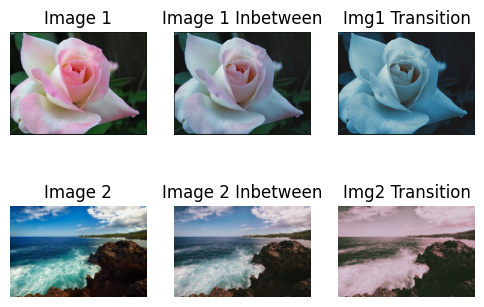

In [7]:
ct = color_transport(img1_name, img2_name)

mid_img1 = (ct[0] + ct[2]) / 2
mid_img2 = (ct[1] + ct[3]) / 2

plt.figure(1, figsize=(6,4))

plt.subplot(2, 3, 1)
plt.imshow(ct[0])
plt.axis("off")
plt.title("Image 1")

plt.subplot(2, 3, 2)
plt.imshow(mid_img1)
plt.axis("off")
plt.title("Image 1 Inbetween")

plt.subplot(2, 3, 3)
plt.imshow(ct[2])
plt.axis("off")
plt.title("Img1 Transition")

plt.subplot(2, 3, 4)
plt.imshow(ct[1])
plt.axis("off")
plt.title("Image 2")

plt.subplot(2, 3, 5)
plt.imshow(mid_img2)
plt.axis("off")
plt.title("Image 2 Inbetween")

plt.subplot(2, 3, 6)
plt.imshow(ct[3])
plt.axis("off")
plt.title("Img2 Transition")

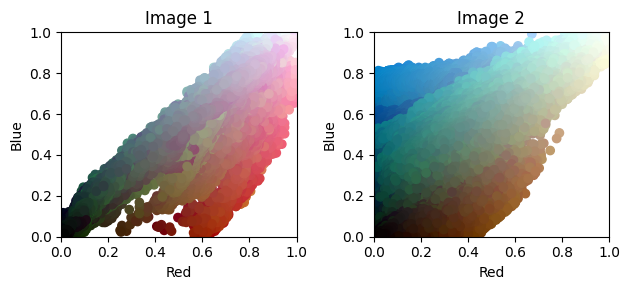

In [8]:
plt.figure(2, figsize=(6.4, 3))

# importing the image from the img folder
img1 = Image.open(img1_name)
img2 = Image.open(img2_name)

# formatting the img to a numpy array with one pixel per line
img1_a = np.array(img1) / 256
img2_a = np.array(img2) / 256

X_source = im2mat(img1_a)
X_target = im2mat(img2_a)

plt.subplot(1, 2, 1)
plt.scatter(X_source[:, 0], X_source[:, 2], c=X_source)
plt.axis([0, 1, 0, 1])
plt.xlabel("Red")
plt.ylabel("Blue")
plt.title("Image 1")

plt.subplot(1, 2, 2)
plt.scatter(X_target[:, 0], X_target[:, 2], c=X_target)
plt.axis([0, 1, 0, 1])
plt.xlabel("Red")
plt.ylabel("Blue")
plt.title("Image 2")
plt.tight_layout()